# Plots for presentation
This notebook provides simplified and specific plots used for presentations and papers.
- It uses the created `long__xy.parquet` files as base information about the dataset.
- the framework `nnrun` is used for creation of matrices.

## Libraries
First of all import all relevant libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
import matplotlib as mpl
from pathlib import Path
from typing import Any, Dict, List
import yaml


Set plot to default

In [2]:
plt.style.use("default")  # reset to Matplotlib default (light)
mpl.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "savefig.transparent": False,
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
})

out_dir = Path(f"plots/presentation/")
out_dir.mkdir(parents=True, exist_ok=True)

## Create visualization of cross-overs

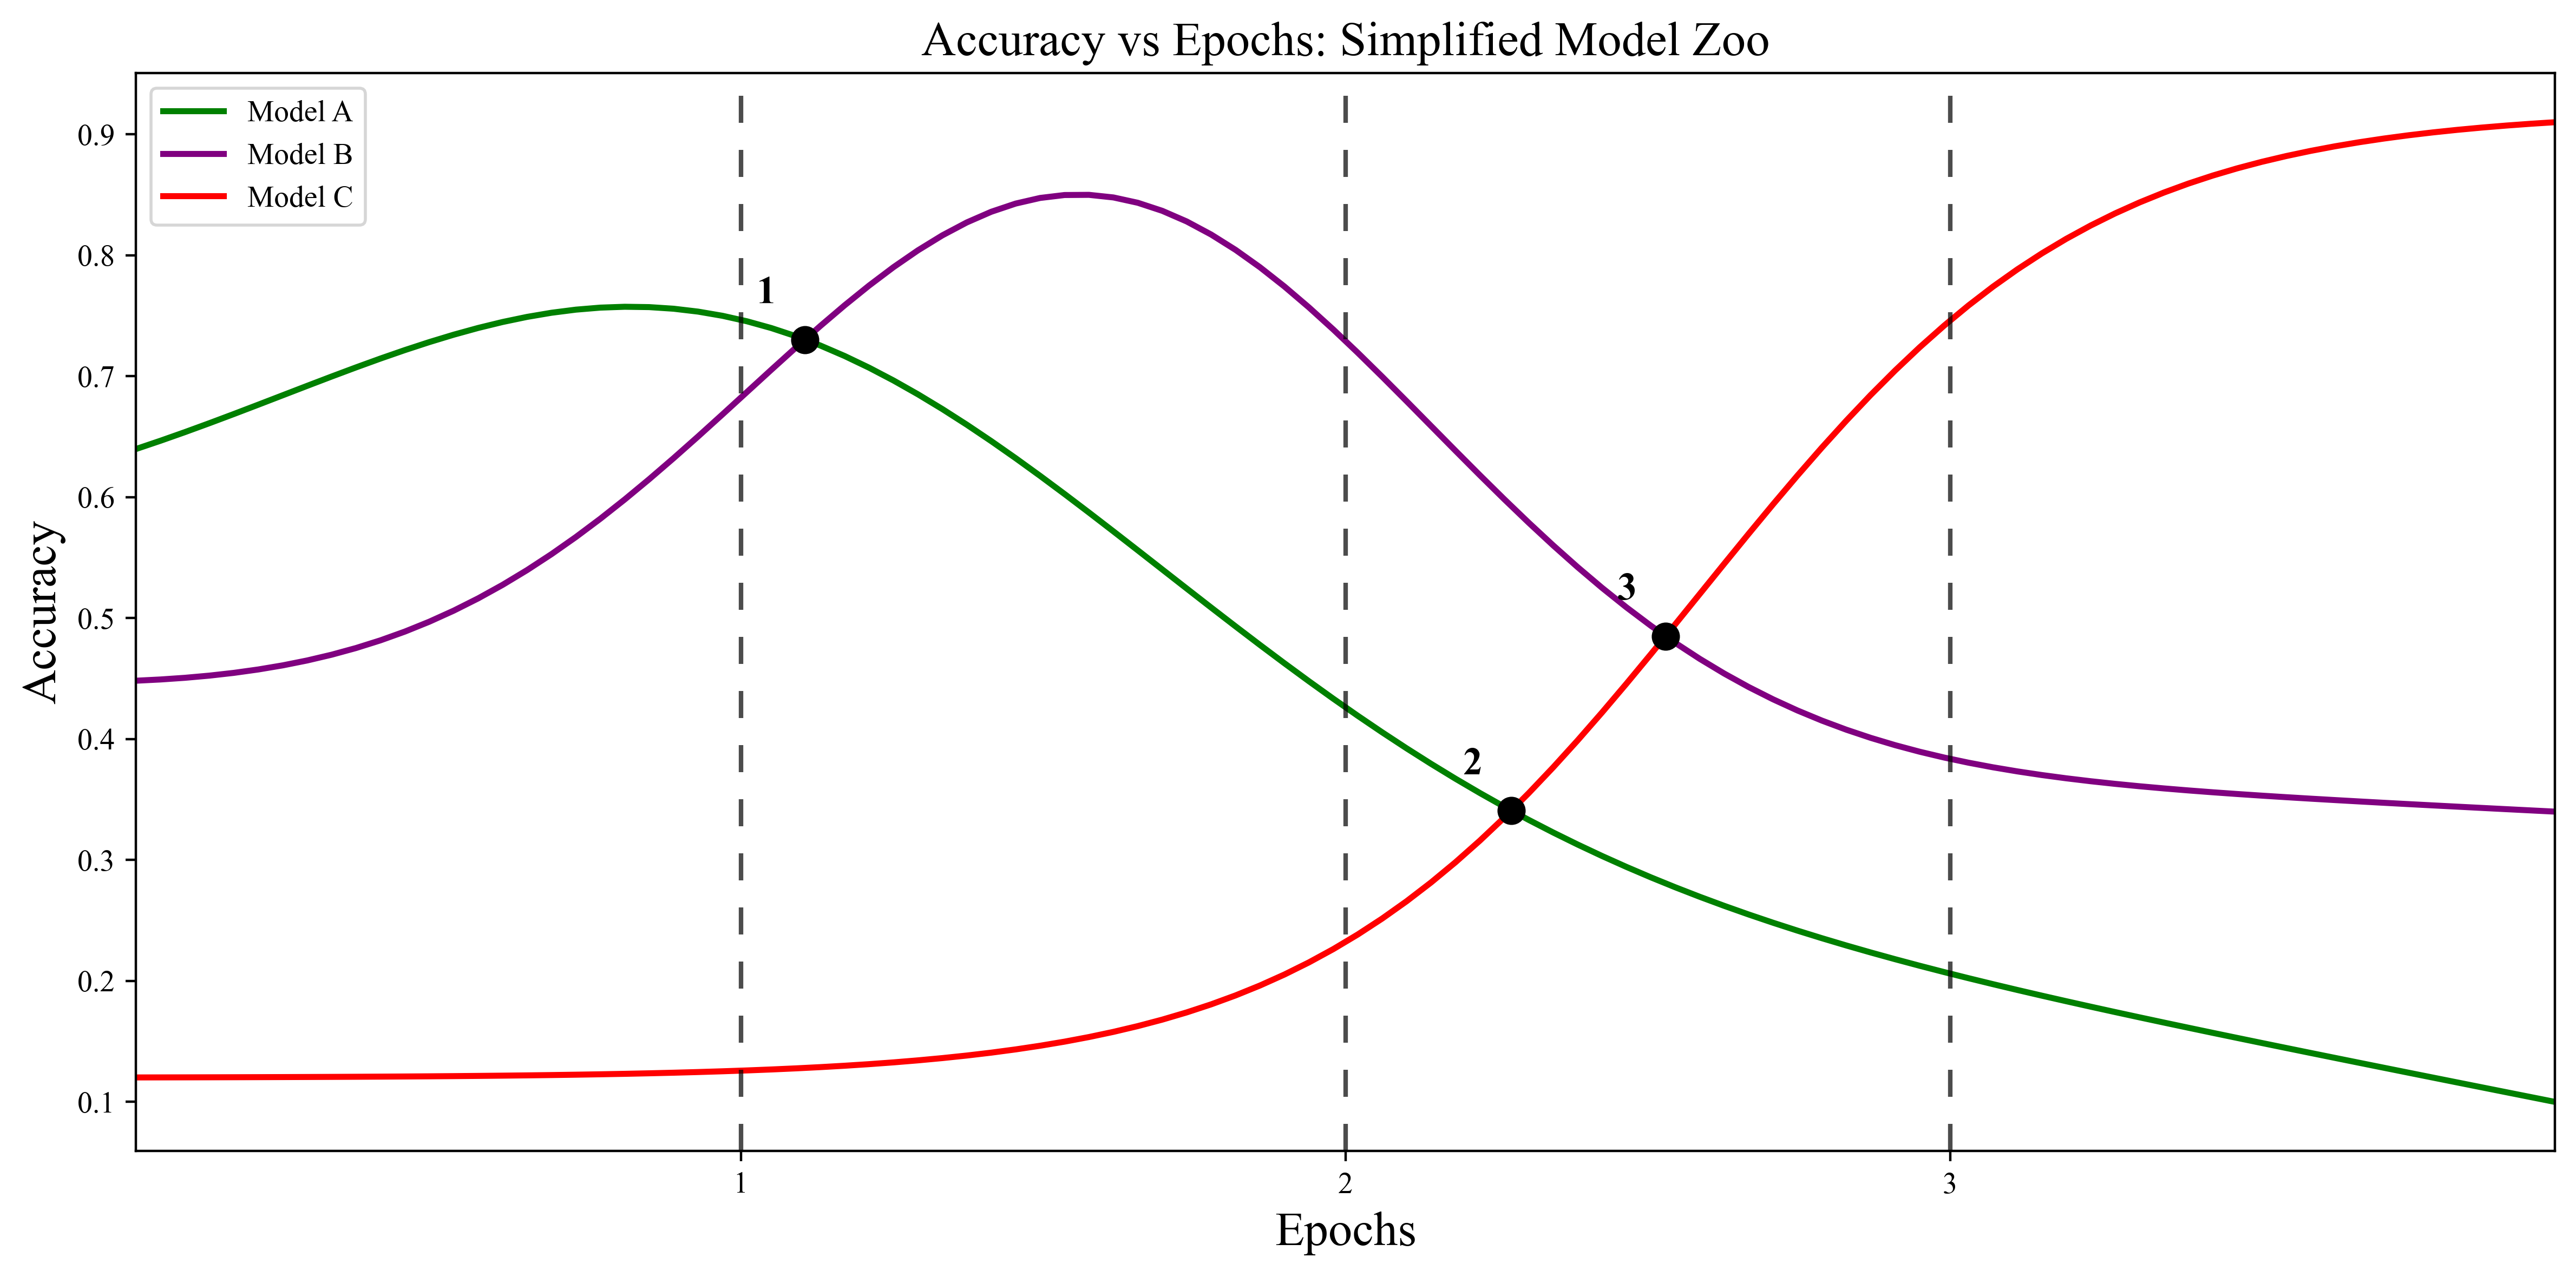

In [3]:
def all_intersections(x, curves, names=None):
    """
    Find all pairwise intersections between multiple curves y(x).
    Returns a list of dicts with keys: x, y, pair=(i,j)
    """
    curves = [np.asarray(y) for y in curves]
    n = len(curves)
    if names is None:
        names = [f"Curve {i}" for i in range(n)]

    intersections = []

    for i, j in combinations(range(n), 2):
        y1, y2 = curves[i], curves[j]
        d = y1 - y2

        # sign-change indicates a crossing in segment [k, k+1]
        # treat exact zeros robustly by looking for sign changes in consecutive samples
        s = np.sign(d)
        s[s == 0] = np.nan  # temporarily ignore exact zeros
        # forward-fill / backward-fill zeros to nearest non-zero sign
        # (simple approach: use sign of nearest neighbor)
        s2 = np.copy(s)
        for k in range(1, len(s2)):
            if np.isnan(s2[k]):
                s2[k] = s2[k-1]
        for k in range(len(s2)-2, -1, -1):
            if np.isnan(s2[k]):
                s2[k] = s2[k+1]
        s2[np.isnan(s2)] = 0  # if everything was zero, fallback

        idx = np.where(s2[:-1] * s2[1:] < 0)[0]

        for k in idx:
            # linear interpolation for intersection in [k, k+1]
            x0, x1 = x[k], x[k+1]
            d0, d1 = d[k], d[k+1]
            if d0 == d1:
                continue  # degenerate; skip

            t = d0 / (d0 - d1)  # fraction from k to k+1 where d=0
            xi = x0 + t * (x1 - x0)
            yi = y1[k] + t * (y1[k+1] - y1[k])

            intersections.append({"x": xi, "y": yi, "pair": (i, j)})

    # sort left-to-right
    intersections.sort(key=lambda p: p["x"])
    return intersections


epochs = np.arange(1, 101)

model_a = 0.50 + 0.35*np.exp(-(epochs-25)**2/(2*18**2)) - 0.004*epochs
model_b = 0.40 + 0.45*np.exp(-(epochs-40)**2/(2*14**2)) - 0.0010*(epochs-40)
low, high = 0.12, 0.92
mid, sharp = 65, 8

model_c = low + (high - low) / (1 + np.exp(-(epochs - mid) / sharp))

curves = [model_a, model_b, model_c]
names  = ["Model A", "Model B", "Model C"]
colors = ["green", "purple", "red"]

# Map real epochs -> schematic axis [0,4] so you can draw epoch markers at 1,2,3
x = (epochs - epochs.min()) / (epochs.max() - epochs.min()) * 4.0

# Find all intersections
ints = all_intersections(x, curves, names=names)

# Plot
fig, ax = plt.subplots(figsize=(12, 6), dpi=400)

for y, name, c in zip(curves, names, colors):
    ax.plot(x, y, lw=2, color=c, label=name)

# Dashed epoch markers (fixed at 1,2,3)
for e in [1, 2, 3]:
    ax.axvline(e, color="black", lw=1.5, ls=(0, (6, 6)), alpha=0.7)

# Plot and number every intersection
for idx, p in enumerate(ints, start=1):
    px, py = p["x"], p["y"]
    ax.scatter(px, py, color="black", s=70, zorder=5)
    ax.text(px - 0.08, py + 0.03, str(idx), fontsize=13, weight="bold")

# Labels, legend, styling
ax.set_xlabel("Epochs", fontsize=16)
ax.set_ylabel("Accuracy", fontsize=16)

ax.set_xlim(0, 4)
ax.set_xticks([1, 2, 3])
ax.set_xticklabels(["1", "2", "3"])
ax.set_title("Accuracy vs Epochs: Simplified Model Zoo", fontsize=16)
ax.legend(loc="best", frameon=True)


plt.tight_layout()
plt.show()
fig.savefig(out_dir / f"1_crossovers_simplified.pdf", bbox_inches="tight")
fig.savefig(out_dir / f"1_crossovers_simplified.png", dpi=200, bbox_inches="tight", facecolor="white")

## Create visualization of late bloomers and early faders

Shows a simplified model zoo where:
- **Late Bloomer**: ranked in the **bottom 30%** at *t_mid* but rises to the **top 30%** by *t_end*
- **Early Fader**: ranked in the **top 30%** at *t_mid* but falls to the **bottom 30%** by *t_end*

The shaded bands reflect the 30th / 70th percentile thresholds computed across all models at *t_mid* (left) and *t_end* (right).

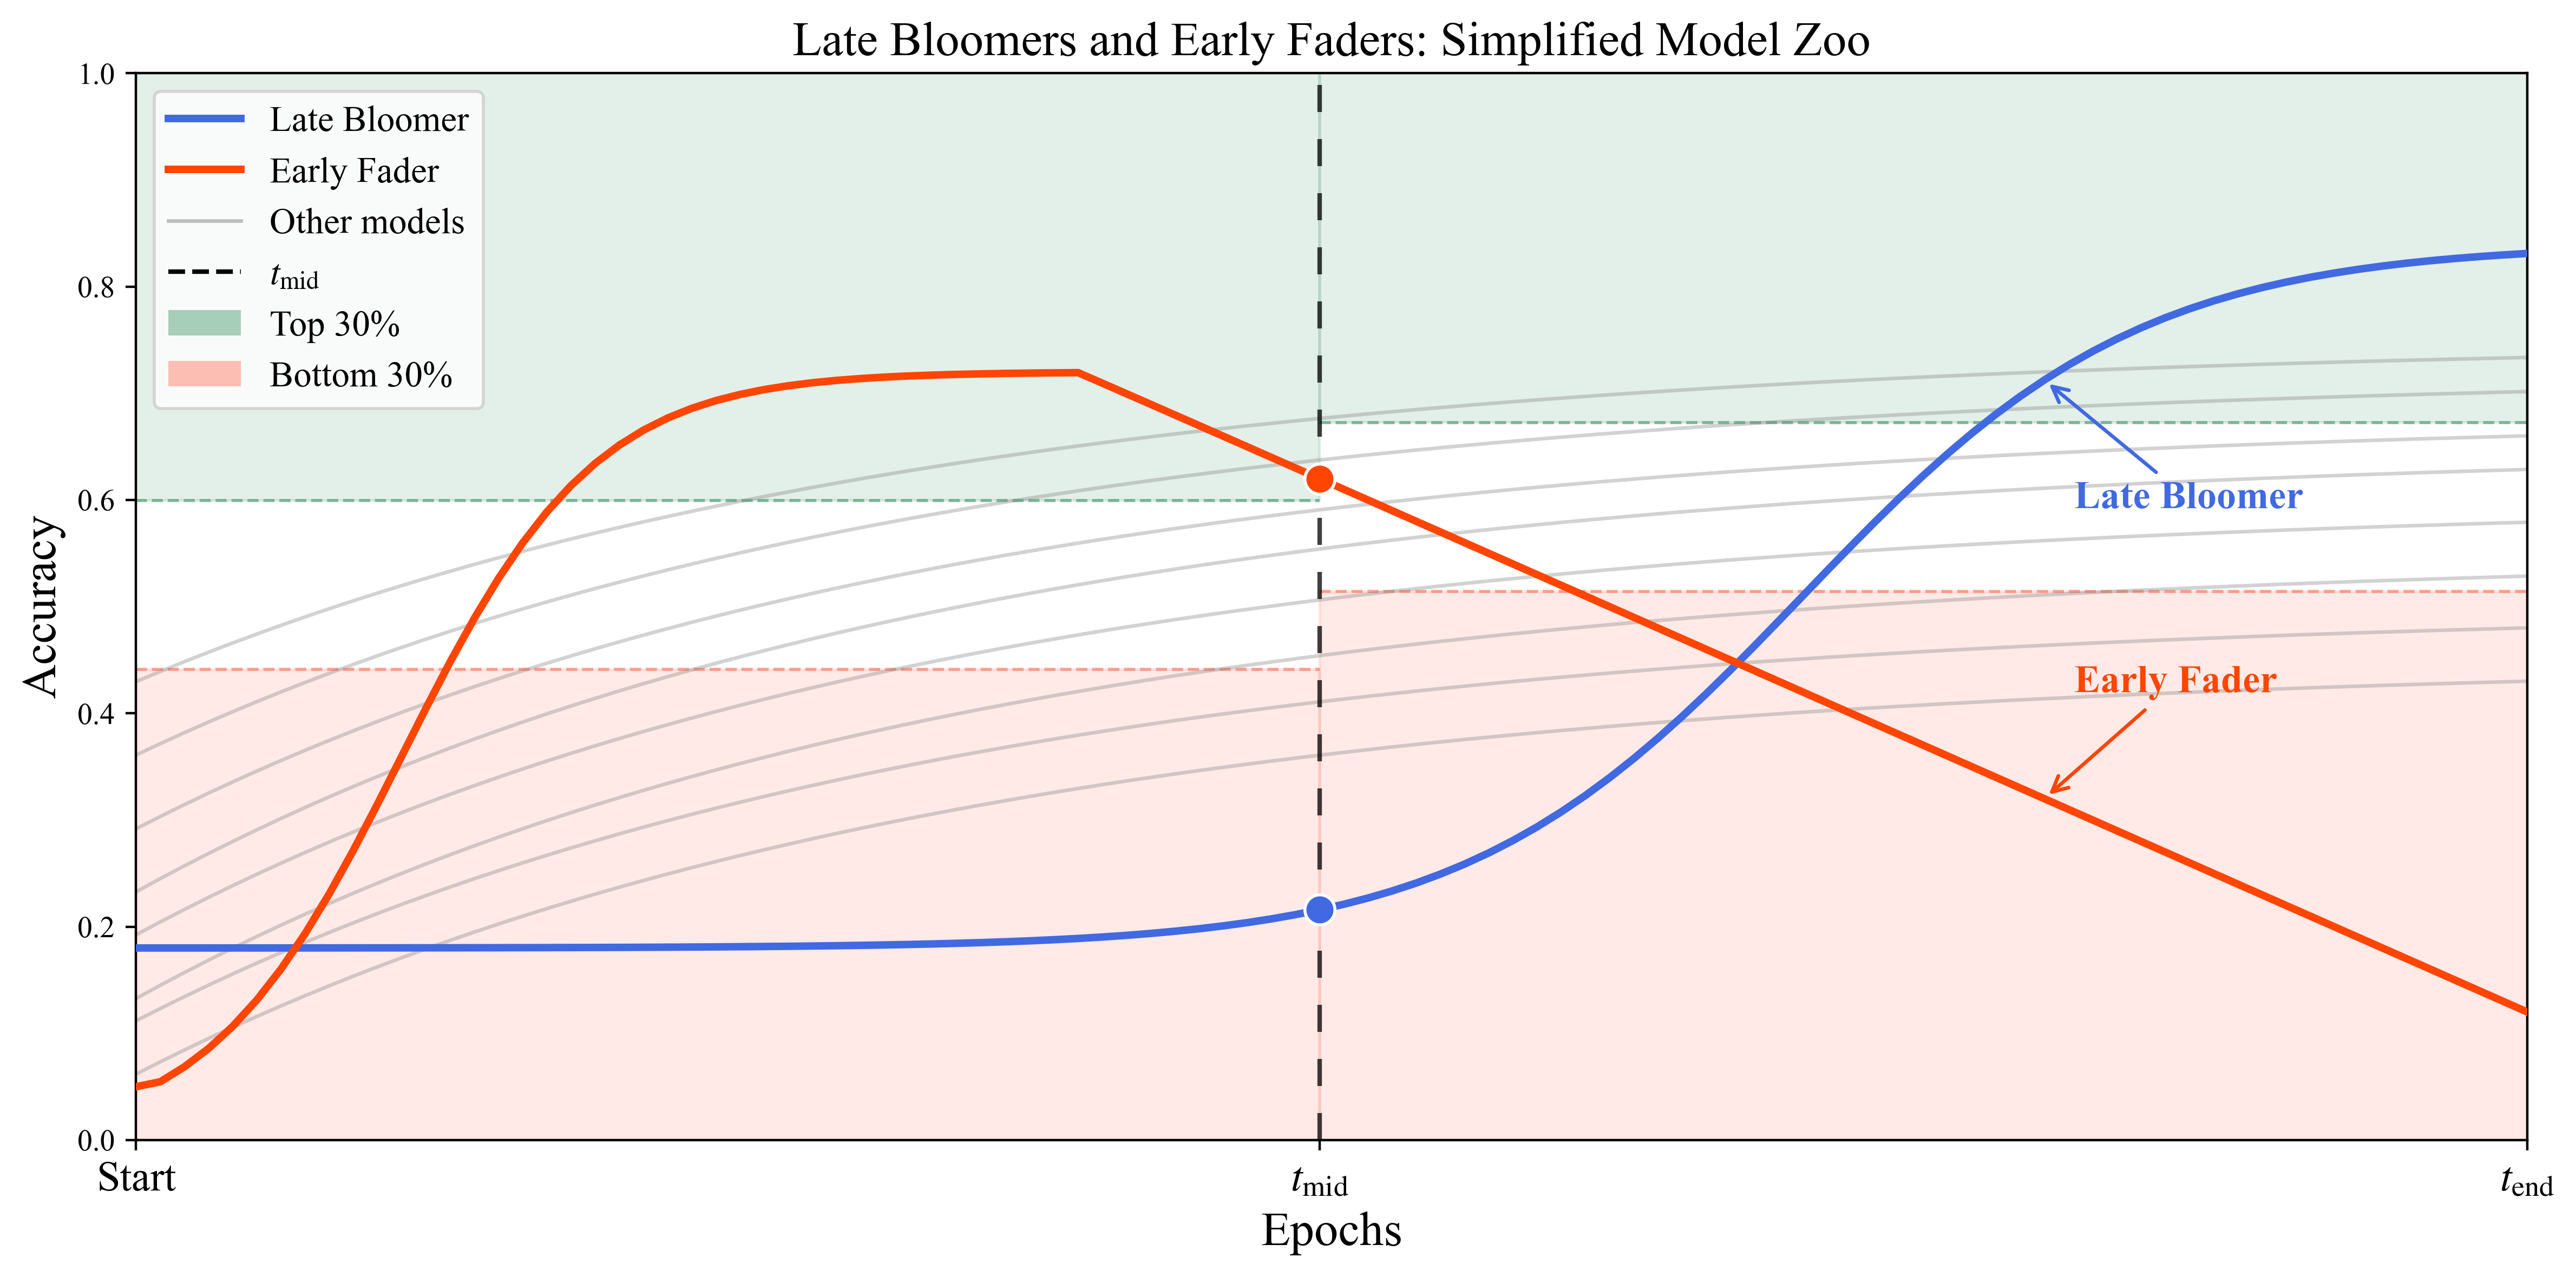

In [4]:
from matplotlib.patches import Patch

# ── Schematic epoch axis ──────────────────────────────────────────────────────
epochs = np.arange(1, 101)
x_full = (epochs - 1) / 99 * 4   # map epochs [1..100] → x [0..4]

mid_epoch = 50
end_epoch = 100
mid_idx = np.argmin(np.abs(epochs - mid_epoch))
end_idx  = np.argmin(np.abs(epochs - end_epoch))
mid_x    = float(x_full[mid_idx])   # = 2.0

# ── Background model curves ───────────────────────────────────────────────────
def exp_curve(epochs, start, end, k=0.03):
    """Simple exponential approach to a final accuracy value."""
    return end - (end - start) * np.exp(-k * epochs)

bg_params = [
    (0.05, 0.45), (0.10, 0.50), (0.12, 0.55), (0.18, 0.60),
    (0.22, 0.65), (0.28, 0.68), (0.35, 0.72), (0.42, 0.75),
]
bg_curves = [exp_curve(epochs, s, e) for s, e in bg_params]

# ── Special curves ────────────────────────────────────────────────────────────
# Late bloomer: dormant until ~epoch 65, then surges to the top
late_bloomer = 0.18 + 0.66 / (1 + np.exp(-(epochs - 70) / 7))

# Early fader: rapid early learner that plateaus then declines after epoch 40
fast_grow   = 0.72 / (1 + np.exp(-(epochs - 12) / 4))
linear_drop = 0.010 * np.maximum(0, epochs - 40)
early_fader = np.clip(fast_grow - linear_drop, 0.05, 1.0)

# ── 30th / 70th percentile thresholds at mid and end ─────────────────────────
all_curves = bg_curves + [late_bloomer, early_fader]
mid_vals   = np.array([y[mid_idx] for y in all_curves])
end_vals   = np.array([y[end_idx] for y in all_curves])

bot30_mid = float(np.percentile(mid_vals, 30))
top30_mid = float(np.percentile(mid_vals, 70))
bot30_end = float(np.percentile(end_vals, 30))
top30_end = float(np.percentile(end_vals, 70))

# ── Figure ────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 6), dpi=400)

# Shaded bands — left of t_mid (thresholds based on mid-epoch ranks)
ax.fill_between([0, mid_x], [0]*2,         [bot30_mid]*2, color='tomato',   alpha=0.13, zorder=0)
ax.fill_between([0, mid_x], [top30_mid]*2, [1]*2,         color='seagreen', alpha=0.13, zorder=0)

# Shaded bands — right of t_mid (thresholds based on end-epoch ranks)
ax.fill_between([mid_x, 4], [0]*2,         [bot30_end]*2, color='tomato',   alpha=0.13, zorder=0)
ax.fill_between([mid_x, 4], [top30_end]*2, [1]*2,         color='seagreen', alpha=0.13, zorder=0)

# Dashed threshold lines (one pair per side)
for xl, xr, yb, yt in [(0, mid_x, bot30_mid, top30_mid), (mid_x, 4, bot30_end, top30_end)]:
    ax.plot([xl, xr], [yb]*2, color='tomato',   lw=1.0, ls='--', alpha=0.55)
    ax.plot([xl, xr], [yt]*2, color='seagreen', lw=1.0, ls='--', alpha=0.55)

# Background models
for y in bg_curves:
    ax.plot(x_full, y, lw=1.2, color='gray', alpha=0.35)

# t_mid vertical line
ax.axvline(mid_x, color='black', lw=1.5, ls=(0, (6, 6)), alpha=0.75, zorder=4)

# Special model curves
ax.plot(x_full, late_bloomer, lw=2.5, color='royalblue', zorder=5)
ax.plot(x_full, early_fader,  lw=2.5, color='orangered',  zorder=5)

# Filled markers at t_mid showing each model's position in the ranking
ax.scatter([mid_x], [late_bloomer[mid_idx]], color='royalblue', s=100, zorder=6,
           edgecolors='white', linewidths=1.0)
ax.scatter([mid_x], [early_fader[mid_idx]],  color='orangered',  s=100, zorder=6,
           edgecolors='white', linewidths=1.0)

# Curve labels placed where they are unambiguous
ax.annotate(
    "Late Bloomer",
    xy=(x_full[79], late_bloomer[79]), xytext=(x_full[79] + 0.05, late_bloomer[79] - 0.12),
    fontsize=13, color='royalblue', fontweight='bold',
    arrowprops=dict(arrowstyle='->', color='royalblue', lw=1.2),
)
ax.annotate(
    "Early Fader",
    xy=(x_full[79], early_fader[79]), xytext=(x_full[79] + 0.05, early_fader[79] + 0.10),
    fontsize=13, color='orangered', fontweight='bold',
    arrowprops=dict(arrowstyle='->', color='orangered', lw=1.2),
)

# Legend
legend_handles = [
    plt.Line2D([0],[0], color='royalblue', lw=2.5,          label='Late Bloomer'),
    plt.Line2D([0],[0], color='orangered',  lw=2.5,          label='Early Fader'),
    plt.Line2D([0],[0], color='gray',       lw=1.2, alpha=0.5, label='Other models'),
    plt.Line2D([0],[0], color='black',      lw=1.5, ls='--', label=r'$t_{\mathrm{mid}}$'),
    Patch(facecolor='seagreen', alpha=0.40,                  label='Top 30%'),
    Patch(facecolor='tomato',   alpha=0.40,                  label='Bottom 30%'),
]
ax.legend(handles=legend_handles, loc='upper left', frameon=True, fontsize=12)

# Axes / styling
ax.set_xlabel("Epochs", fontsize=16)
ax.set_ylabel("Accuracy", fontsize=16)
ax.set_xlim(0, 4)
ax.set_ylim(0, 1)
ax.set_xticks([0, mid_x, 4])
ax.set_xticklabels(["Start", r"$t_{\mathrm{mid}}$", r"$t_{\mathrm{end}}$"], fontsize=14)
ax.set_title("Late Bloomers and Early Faders: Simplified Model Zoo", fontsize=16)

plt.tight_layout()
plt.show()
fig.savefig(out_dir / "2_late_bloomers_early_faders.pdf", bbox_inches="tight")
fig.savefig(out_dir / "2_late_bloomers_early_faders.png", dpi=200, bbox_inches="tight", facecolor="white")